# Strip waveguide S-bend 
This notebook contains code that simulates bend waveguide parameters using **Tidy3d**. \
The objective is to obtain loss values across radius sweep.

https://www.flexcompute.com/tidy3d/examples/notebooks/SbendCMAES

In [28]:
%%capture

# Install dependencies specified in pyproject.toml
!uv pip install --reinstall --refresh -r pyproject.toml

# Import modules
import cma
from IPython.display import display
import math
import matplotlib.pyplot as plt
import numpy as np
import photonix as px
import tidy3d as td
import tidy3d.web as web
td.web = web

In [29]:
# Tidy3d version
print(f"Tidy3d version: {td.__version__}")

Tidy3d version: 2.12.2


In [30]:
%%html

<!-- Align table to the left -->
<style>
  table {margin-left: 0 !important;}
</style>

In [31]:
# Constants

um = 1e-6
nm = 1e-9

# Simulation input

| Parameter                 | Description                                                                                   | Example                |
| :------------------------ | :-------------------------------------------------------------------------------------------- | :--------------------- |
| **wavelength_center**     | Wavelength for which simulation will be done. (i)                                             | `1.55*um`              |
| **core_thickness**        | Thickness of the burried oxide strip waveguide core.                                          | `220*nm`               |
| **core_width**            | Width of the strip waveguide core.                                                            | `500*nm`               |
| **core material**         | Material of strip waveguide core as defined in materials library of specified solver backend. | `Si (Silicon) - Palik` |
| **clad material**         | Material of strip waveguide clad as defined in materials library of specified solver backend. | `SiO2 (Glass) - Palik` |
| **top_clad_thickness**    | Thickness of the top clad layer.                                                              | `5*µm`                 |
| **bottom_clad_thickness** | Thickness of the bottom clad layer.                                                           | `5*µm`                 |

`top_clad_thickness` and `bottom_clad_thickness` are used to pre-calculate FDE window size. \
They are not that relevant from the simulation perspective but setting too large values will result in longer computation time during intial FDE size optimization.

In [32]:
# Si/SiO2 430x220nm 1550nm
wavelength_center = 1.55*um
wavelength_span = 0.30*um
field_intensity_log_decay = -6

core_thickness = 220*nm
core_width = 430*nm

sbend_length = 3.5*um
sbend_width = 3.5*um

bottom_clad_thickness = 3*um
top_clad_thickness = 2*um

# https://docs.flexcompute.com/projects/tidy3d/en/stable/api/material_library.html
core_material = "cSi Palik_LowLoss"
clad_material = "SiO2 Palik_LowLoss"
substrate_material = "cSi Palik_LowLoss"

In [6]:
# Si3N4/SiO2 1000x360nm 1550nm
wavelength_center = 1.55*um
wavelength_span = 0.30*um
field_intensity_log_decay = -6

core_thickness = 360*nm
core_width = 1000*nm

sbend_length = 15*um
sbend_width = 5*um

bottom_clad_thickness = 3*um
top_clad_thickness = 2*um

# https://docs.flexcompute.com/projects/tidy3d/en/stable/api/material_library.html
core_material = "cSi Palik_LowLoss"
clad_material = "SiO2 Palik_LowLoss"
substrate_material = "cSi Palik_LowLoss"

In [33]:
#wavelength_center
#wavelength_span

#core_thickness
#core_width

#sbend_length
#sbend_width

#bottom_clad_thickness
#top_clad_thickness

ports_offset = sbend_length/20
initial_ports_width = 4*core_width
initial_ports_height = 6*core_thickness

initial_fdtd_height = initial_port_height + 2*wavelength_center
initial_fdtd_length = sbend_length + 2*ports_offset + 2*wavelength_center
initial_fdtd_width = sbend_width + initial_port_width + 2*wavelength_center

In [34]:
wavelength_center_um = wavelength_center * 1e6
wavelength_span_um = wavelength_span *1e6

core_thickness_um = core_thickness*1e6
core_width_um = core_width*1e6

sbend_length_um = sbend_length*1e6
sbend_width_um = sbend_width*1e6

bottom_clad_thickness_um = bottom_clad_thickness*1e6
top_clad_thickness_um = top_clad_thickness*1e6

ports_offset_um = ports_offset*1e6
initial_ports_width_um = initial_port_width*1e6
initial_ports_height_um = initial_port_height*1e6

initial_fdtd_height_um = initial_fdtd_height*1e6
initial_fdtd_length_um = initial_fdtd_length*1e6
initial_fdtd_width_um = initial_fdtd_width*1e6

In [35]:
wavelengths = np.arange(wavelength_center - wavelength_span/2, wavelength_center + wavelength_span/2, 0.01*um)

frequency_center = (td.C_0*1e-6)/wavelength_center
frequency_span = (td.C_0*1e-6)/wavelength_span
frequencies = (td.C_0*1e-6)/ wavelengths

In [36]:
# Materials fitting

# Helper to fit materials
def fit_material(material_name):
    material_name, material_model = material_name.split()
    material = td.material_library[material_name][material_model]

    # TODO: Check fitting !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
    return material
    
    wavelength_min = wavelength_center - 150*nm
    wavelength_max = wavelength_center + 150*nm
    wavelengths = np.linspace(wavelength_min, wavelength_max, 50)
    freqs = (td.C_0 * 1e-6)/wavelengths

    eps = np.array([material.eps_model(f) for f in freqs])
    n, k = np.real(np.sqrt(eps)), np.imag(np.sqrt(eps))
    fitter = FastDispersionFitter(
      wvl_um=wavelengths*1e6, n_data=n, k_data=k, wvl_range=(wavelength_min*1e6, wavelength_min*1e6)
    )
    fitted, _ = fitter.fit(min_num_poles=1, max_num_poles=6, tolerance_rms=0.001)
    return fitted

core_material = fit_material(core_material)
clad_material = fit_material(clad_material)
substrate_material = fit_material(substrate_material)

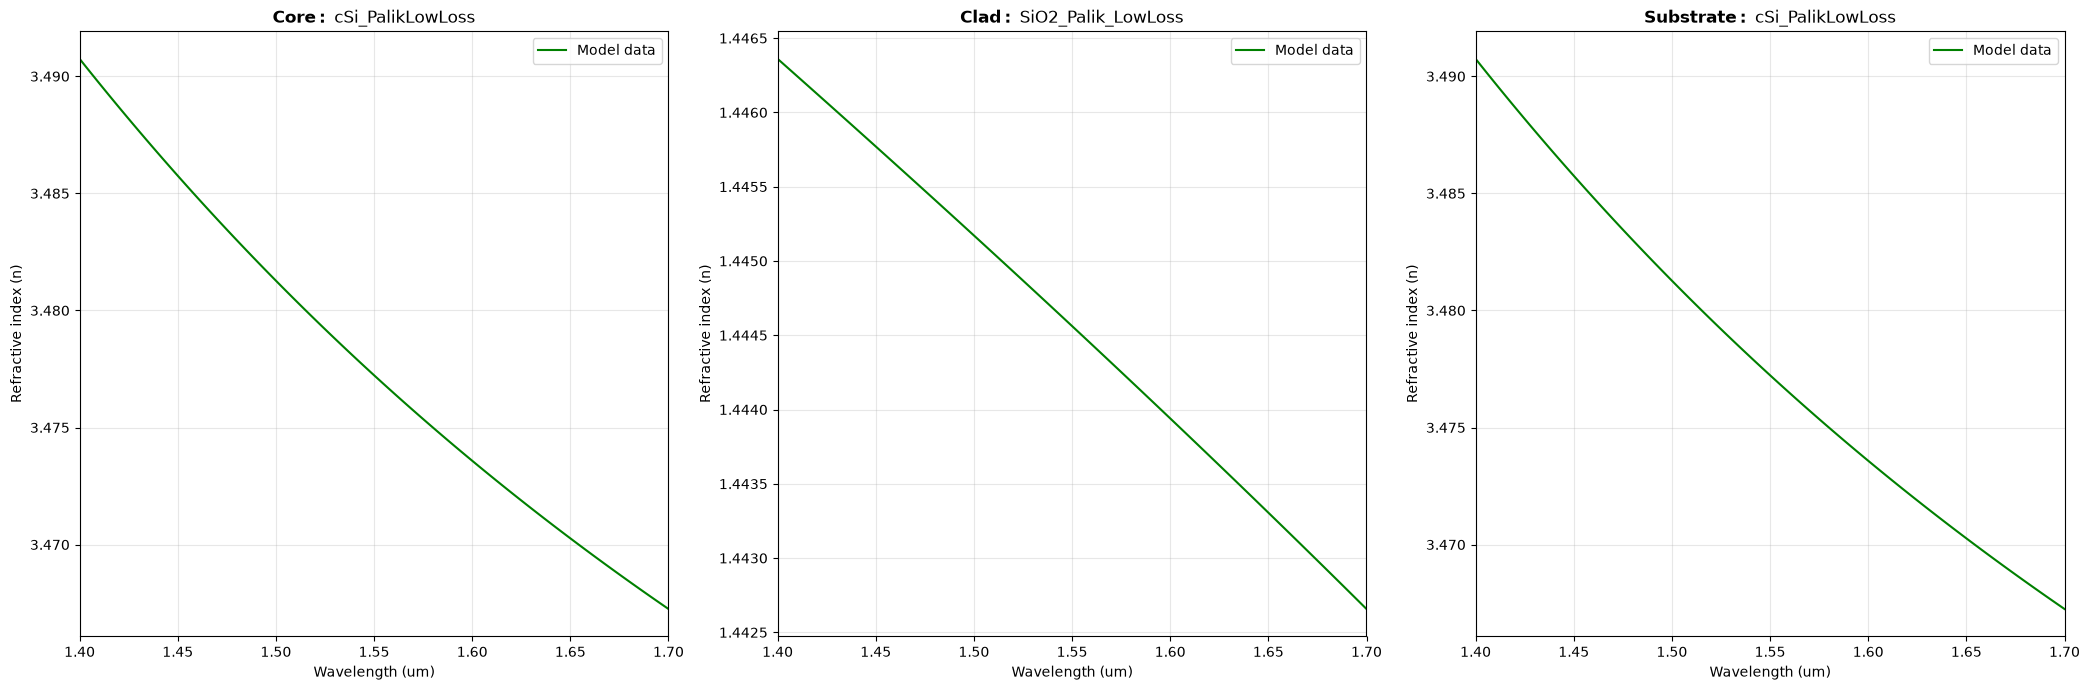

In [37]:
# Materials fit preview

def plot_material(material, ax):
    # ax.set_title(material)

    wvl_min = wavelength_center - 150 * nm
    wvl_max = wavelength_center + 150 * nm
    f1 = (td.C_0 * 1e-6) / np.linspace(wvl_min, wvl_max, 100)

    eps = np.array([material.eps_model(f) for f in f1])
    mat_n_model, mat_k_model = np.real(np.sqrt(eps)), np.imag(np.sqrt(eps))

    mat_n_model = np.column_stack((f1, mat_n_model))

    px.plot_material_n(
        mat_n_model=mat_n_model,
        wavelength_min=wvl_min, wavelength_max=wvl_max,
        ax=ax
    )
    ax.ticklabel_format(axis='y', useOffset=False, style='plain')
    

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(21, 7))

# Core
plot_material(core_material, ax1)
ax1.set_title(f"$\\bf{{Core:}}$ {core_material.name}")

# Clad
plot_material(clad_material, ax2)
ax2.set_title(f"$\\bf{{Clad:}}$ {clad_material.name}")

# Substrate
plot_material(substrate_material, ax3)
ax3.set_title(f"$\\bf{{Substrate:}}$ {substrate_material.name}")

fig.tight_layout()
plt.show()

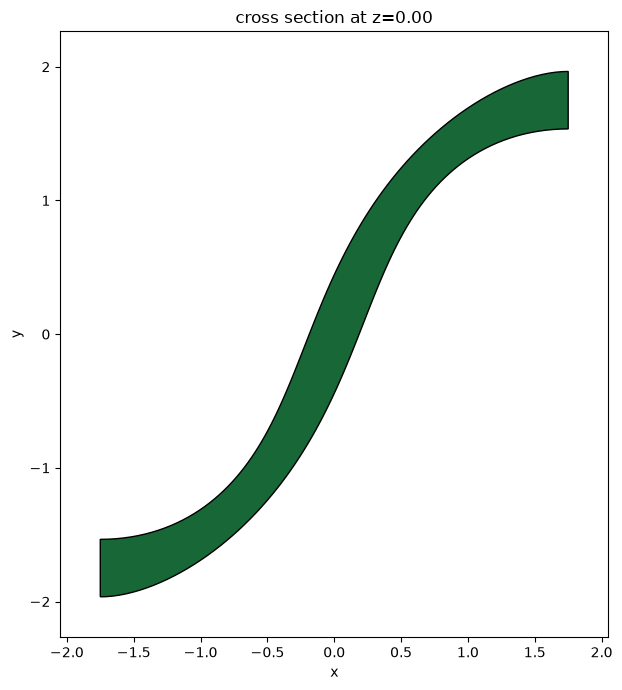

In [38]:
# Structure geometry

# S-bend
def bezier_curve(control_points, num_points=100):
    t = np.linspace(0, 1, num_points)
    curve = np.zeros((num_points, 2))
    n = len(control_points) - 1  # degree of the Bézier curve

    for i in range(n + 1):
        binomial_coeff = math.factorial(n) / (math.factorial(i) * math.factorial(n - i))
        term = binomial_coeff * (1 - t) ** (n - i) * t**i
        curve += np.outer(term, control_points[i])

    return curve

def make_sbend(v):
    p_input = np.array([-sbend_length_um/2, -sbend_width_um/2 - core_width_um/2])
    p_output = np.array([sbend_length_um/2, sbend_width_um/2 - core_width_um/2])

    sbend_bot_points = np.array(
        [
            p_input,
            [v[0], v[1]],
            [v[2], v[3]],
            [v[4], 0],
            [v[5], v[6]],
            [v[7], v[8]],
            p_output,
        ]
    )

    sbend_bot_curve = bezier_curve(sbend_bot_points)
    sbend_top_curve = -sbend_bot_curve

    vertices = np.vstack((sbend_bot_curve, sbend_top_curve))
    sbend = td.Structure(
        name="s-bend",
        geometry=td.PolySlab(
            vertices=vertices, 
            axis=2, 
            slab_bounds=(-core_thickness_um / 2, core_thickness_um / 2)
        ),
        medium=core_material
    )

    return sbend
    

p1 = np.array([-sbend_length_um/4 - core_width_um/4, -sbend_width_um/2 - core_width_um/2])
p2 = np.array([core_width_um/2, -sbend_width_um/4 - core_width_um/4])
p3 = np.array([core_width_um/2, 0])
p4 = np.array([core_width_um/2, sbend_width_um/4 - core_width_um/4])
p5 = np.array([sbend_length_um/4 - core_width_um/4, sbend_width_um/2 - core_width_um/2])

sbend_initial_v = np.array([
    p1[0], p1[1],
    p2[0], p2[1],
    p3[0],
    p4[0], p4[1],
    p5[0], p5[1]
])

sbend = make_sbend(sbend_initial_v)

# Input wavegoude
waveguide_in = td.Structure(
    name="waveguide_in",
    geometry=td.Box.from_bounds(
        rmin=(
            -100,
            -sbend_width_um/2 - core_width_um/2, 
            -core_thickness_um/2
        ), 
        rmax=(
            -sbend_length_um/2, 
            -sbend_width_um/2 + core_width_um/2, 
            core_thickness_um/2
        ),
    ),
    medium=core_material,
)

# Output wavegoude
waveguide_out = td.Structure(
    name="waveguide_out",
    geometry=td.Box.from_bounds(
        rmin=(
            sbend_length_um/2,
            sbend_width_um/2 - core_width_um/2, 
            -core_thickness_um/2
        ), 
        rmax=(
            100, 
            sbend_width_um/2 + core_width_um/2, 
            core_thickness_um/2
        ),
    ),
    medium=core_material,
)

# S-bend preview
fig, ax = plt.subplots(1, 1, figsize=(14, 7))

sbend.plot(z=0, ax=ax)
ax2.set_title("Tidy3D PolySlab Structure")

plt.tight_layout()
plt.show()

In [46]:
# Simulation setup

mode_spec = td.ModeSpec(num_modes=1)

# Mode source
mode_source = td.ModeSource(
    name="source",
    center=(
        -sbend_length_um/2 - ports_offset_um, 
        -sbend_width_um/2, 
        0
    ),
    size=(
        0, 
        initial_ports_width_um, 
        initial_ports_height_um
    ),
    source_time=td.GaussianPulse(
        freq0=frequency_center, 
        fwidth=frequency_span/2
    ),
    direction="+",
    mode_spec=mode_spec,
    mode_index=0,
)

# Mode monitor
mode_monitor = td.ModeMonitor(
    name="mode_monitor",
    center=(
        sbend_length_um/2 + ports_offset_um,
        sbend_width_um/2,
        0
    ),
    size=mode_source.size,
    freqs=frequencies,
    mode_spec=mode_spec,
)

# Field monitor
field_monitor = td.FieldMonitor(
    name="field_monitor",
    center=(0, 0, 0),
    size=(td.inf, td.inf, 0),
    freqs=frequencies,
)

def make_sim(v, include_fmonitor=False):
    sbend = make_sbend(v)

    monitors = [mode_monitor]
    if include_fmonitor:
        monitors.append(field_monitor)

    return td.Simulation(
        size=(
            initial_fdtd_length_um, 
            initial_fdtd_width_um, 
            initial_fdtd_height_um
        ),
        grid_spec=td.GridSpec.auto(
            min_steps_per_wvl=15, 
            wavelength=wavelength_center_um
        ),
        structures=[waveguide_in, waveguide_out, sbend],
        sources=[mode_source],
        monitors=monitors,
        run_time=3e-13,
        # run_time=3e-12,
        # shutoff=1e-5,
        boundary_spec=td.BoundarySpec.all_sides(boundary=td.PML()),
        medium=clad_material,
        symmetry=(0, 0, 1),
    )

In [47]:
# Simulation preview
sim = make_sim(sbend_initial_v, include_fmonitor = True)
sim.plot_3d()

# Cost estimate
job = td.web.Job(
    simulation=sim,
    task_name="S-bend initial simulation"
)

estimated_cost = job.estimate_cost()
print(f"Estimated cost for initial simulation: {estimated_cost:.3f} FlexCredits")

11:01:01 UTC Created task 'S-bend initial simulation' with resource_id          
             'fdve-1fad7f95-4814-463e-bff4-835189835234' and task_type 'FDTD'.

             View task using web UI at                                          
             ]8;id=2747706;https://tidy3d.simulation.cloud/workbench?taskId=fdve-1fad7f95-4814-463e-bff4-835189835234\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=2747707;https://tidy3d.simulation.cloud/workbench?taskId=fdve-1fad7f95-4814-463e-bff4-835189835234\taskId]8;;\]8;id=2747706;https://tidy3d.simulation.cloud/workbench?taskId=fdve-1fad7f95-4814-463e-bff4-835189835234\=]8;;\]8;id=2747708;https://tidy3d.simulation.cloud/workbench?taskId=fdve-1fad7f95-4814-463e-bff4-835189835234\fdve]8;;\]8;id=2747706;https://tidy3d.simulation.cloud/workbench?taskId=fdve-1fad7f95-4814-463e-bff4-835189835234\-1fad7f95-481]8;;\
             ]8;id=2747706;https://tidy3d.simulation.cloud/workbench?taskId=fdve-1fad7f95-4814-463e-bff4-835189835234\4-463e-bff4-835189835234']8;;\.

             Task folder: ]8;id=2747710;https://tidy3d.simulation.cloud/folders/folder-1b850be5-31d3-4a3b-ba09-99935a83d59f\'default']8;;\.

Output()

11:01:07 UTC Estimated FlexCredit cost: 0.179. This assumes the FDTD solver runs
             for the full simulation time; if early shutoff is reached, the     
             billed cost can be lower. Use 'web.real_cost(task_id)' to get the  
             billed FlexCredit cost after a simulation run.

Estimated cost for initial simulation: 0.179 FlexCredits


In [48]:
# Initial simulation

sim_data = td.web.run(sim, task_name="S-bend initial simulation")

11:01:46 UTC Created task 'S-bend initial simulation' with resource_id          
             'fdve-7f564420-72ce-4b61-ad66-149cd384014f' and task_type 'FDTD'.

             View task using web UI at                                          
             ]8;id=2747714;https://tidy3d.simulation.cloud/workbench?taskId=fdve-7f564420-72ce-4b61-ad66-149cd384014f\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=2747715;https://tidy3d.simulation.cloud/workbench?taskId=fdve-7f564420-72ce-4b61-ad66-149cd384014f\taskId]8;;\]8;id=2747714;https://tidy3d.simulation.cloud/workbench?taskId=fdve-7f564420-72ce-4b61-ad66-149cd384014f\=]8;;\]8;id=2747716;https://tidy3d.simulation.cloud/workbench?taskId=fdve-7f564420-72ce-4b61-ad66-149cd384014f\fdve]8;;\]8;id=2747714;https://tidy3d.simulation.cloud/workbench?taskId=fdve-7f564420-72ce-4b61-ad66-149cd384014f\-7f564420-72c]8;;\
             ]8;id=2747714;https://tidy3d.simulation.cloud/workbench?taskId=fdve-7f564420-72ce-4b61-ad66-149cd384014f\e-4b61-ad66-149cd384014f']8;;\.

             Task folder: ]8;id=2747718;https://tidy3d.simulation.cloud/folders/folder-1b850be5-31d3-4a3b-ba09-99935a83d59f\'default']8;;\.

Output()

11:01:49 UTC Estimated FlexCredit cost: 0.179. This assumes the FDTD solver runs
             for the full simulation time; if early shutoff is reached, the     
             billed cost can be lower. Use 'web.real_cost(task_id)' to get the  
             billed FlexCredit cost after a simulation run.

11:01:52 UTC status = queued

... (11 outputs left out)

Output()

11:04:19 UTC Loading results from simulation_data.hdf5

             WARNING: Simulation final field decay value of 1.0 is greater than 
             the simulation shutoff threshold of 1e-05. Consider running the    
             simulation again with a larger 'run_time' duration for more        
             accurate results.                                                  

             WARNING: Warning messages were found in the solver log. For more   
             information, check 'SimulationData.log' or use                     
             'web.download_log(task_id)'.                                       

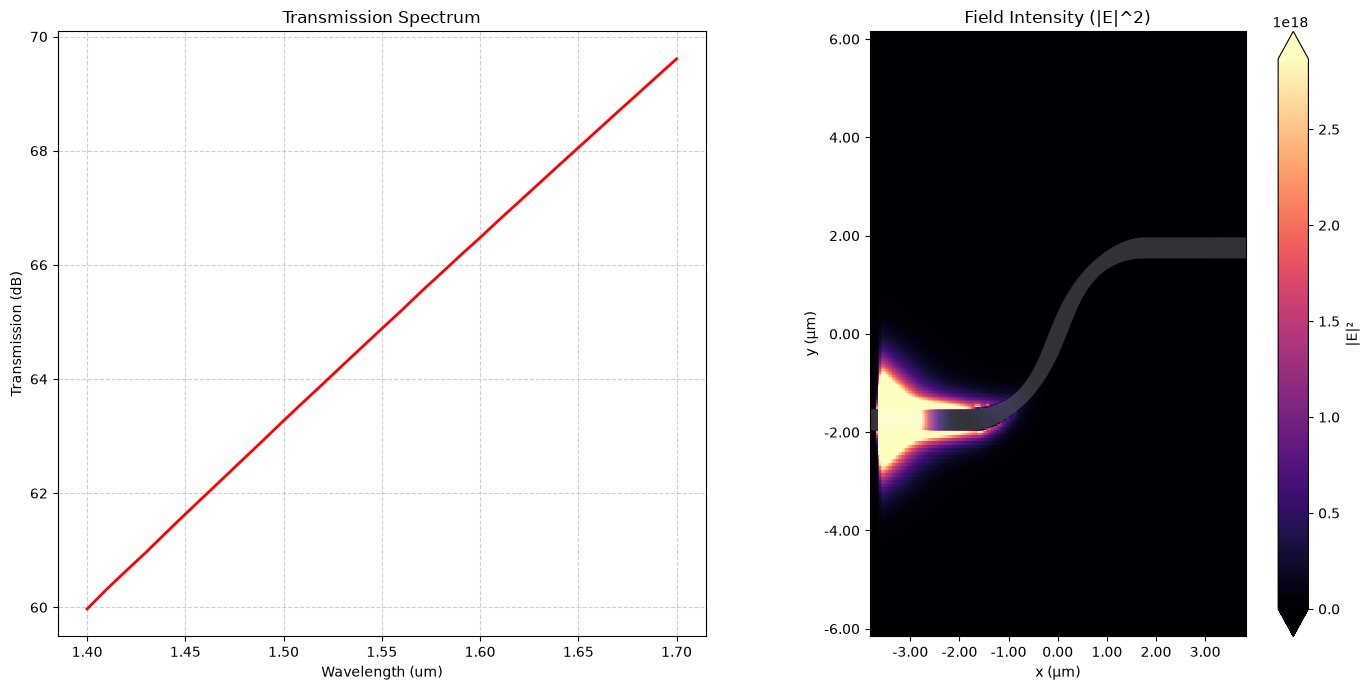

In [49]:
def compute_transmission(sim_data):
    amps = sim_data["mode_monitor"].amps.sel(mode_index=0, direction="+").values
    return np.abs(amps) ** 2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))

T_opt = 10 * np.log10(compute_transmission(sim_data))
ax1.plot(wavelengths * 1e6, T_opt, "red", linewidth=2)
ax1.set_ylabel("Transmission (dB)")
ax1.set_xlabel("Wavelength (um)")
ax1.set_title("Transmission Spectrum")
ax1.grid(True, linestyle="--", alpha=0.6)

sim_data.plot_field(
    field_monitor_name="field_monitor", 
    field_name="E", 
    val="abs^2",
    f=frequency_center,
    ax=ax2,
)
ax2.set_title("Field Intensity (|E|^2)")

plt.tight_layout()
plt.show()

# Optimization

In [ ]:
def objective_function(xs):
    sims = {}
    for i, x in enumerate(xs):
        sim = make_sim(x)
        sims[f"population_{i}"] = sim

    batch = web.Batch(simulations=sims, verbose=False)
    batch_results = batch.run(path_dir="data")

    T = []
    for i, _ in enumerate(xs):
        sim_data = batch_results[f"population_{i}"]
        T.append(-10 * np.log10(np.mean(compute_transmission(sim_data))))
    return T

In [ ]:
dim = len(x0)
population_size = 10
max_generations = 12
sigma0 = 0.05
random_seed = 12345

es = cma.CMAEvolutionStrategy(
    x0, sigma0, {"popsize": population_size, "maxiter": max_generations, "seed": random_seed}
)

In [ ]:
best_values = []

generation = 0
while not es.stop():
    solutions = es.ask()
    function_values = objective_function(solutions)
    es.tell(solutions, function_values)

    best_values.append(es.result[1])

    # Print message for each generation
    print(f"Generation {generation}: Best function value = {es.result[1]:.3f}")

    generation += 1